# Gradient image features: Histogram of Oriented Gradients (HoG) introduction
This exercise is about the extraction of gradient features from images. It offers an introduction and application of HoG features on a sample image.
The HOG features will be used in the exercises next week for classification.

<article class="message">
    <div class="message-body">
        <strong>List of individual tasks</strong>
        <ul style="list-style: none;">
            <li>
            <a href="#descriptor">Task 1: Calculate the HOG descriptor</a>
            </li>
            <li>
            <a href="#test">Task 2: Visualizing and understanding the HOG de…</a>
            </li>
            <li>
            <a href="#compare_images">Task 3: Comparing Hog Features</a>
            </li>
            <li>
            <a href="#interpretation">Task 4: Interpretation/ Understanding questions</a>
            </li>
        </ul>
    </div>
</article>

The cell below loads a sample image.


(480, 852, 3)


Text(0.5, 1.0, 'Input image')

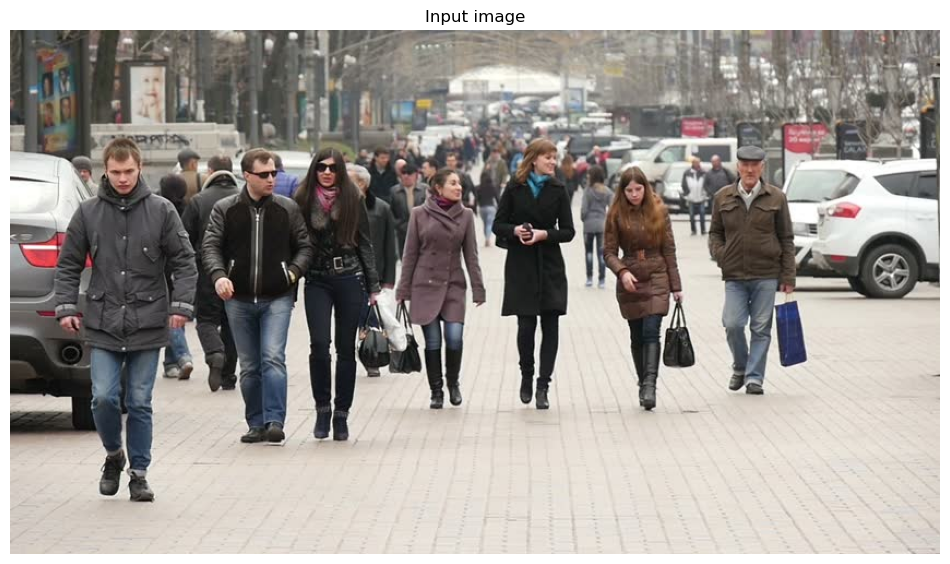

In [1]:
## load input image
import matplotlib.pyplot as plt
import numpy as np
from skimage.feature import hog
from skimage import data, exposure


fn =  "./data/people01.jpg"
image = plt.imread(fn)
print(image.shape)

fig, ax1 = plt.subplots(figsize=(12, 8), sharex=True, sharey=True)

ax1.axis('off')
ax1.imshow(image, cmap=plt.cm.gray)
ax1.set_title('Input image')

In the following section: 
- you are introduced to the [HOG descriptor](https://en.wikipedia.org/wiki/Histogram_of_oriented_gradients)

- shown how to calculate a HoG featues for an image including a visualization of the HoG descriptor.

## Overview of Histogram of Oriented Gradients (HOG) Algorithm
The Histogram of Oriented Gradients (HOG) is a feature descriptor used in computer vision to detect objects. 
The function [skimage.feature.hog](https://scikit-image.org/docs/stable/api/skimage.feature.html<elem-2>.feature.hog)
 computes
the HOG features. It also returns the feature descriptor vector (`fd`
), in which its
size is equal to the number of: Bins $\times$ Block Columns
$\times$ Block Rows $\times$ Cells in the Block.
The process involves the following stages:


**1. Preprocessing / Smoothing:**
Initially, the image undergoes a global intensity normalization — a procedure that diminishes the effects of lighting. A common technique involves gamma (power-law) compression, which can be achieved by calculating the square root or logarithm of each color channel. This stage helps in reducing the impact of local shadowing and highlights variations since the image texture strength is generally related to the local surface illumination.


**2. Calculation of Image Gradients:**


This stage focuses on computing image gradients. The standard procedure is to either convert the image to grayscale or use the most prominent color channel. 
**Info**
This step was implemented by us in the first part of the exercise.

 
**3. Creation of Cells and Calculation of normalized Histograms:**


The objective here is to create an encoding of local gradients. This involves partitioning the image window into smaller spatial cells. Each cell creates a histogram of image gradient orientations and performs various steps to normalize intensities and histograms. 


**4. Compilation of Feature Vector:**


The HOG feature is constructed by concatenating the histograms for each cell into one final HOG feature descriptor (vector). 

---
**Task 1 (easy): Calculate the HOG descriptor👩‍💻**
1. Run the cell below to calculate and plot the HOG descriptor. 


---

(270, 220, 3)


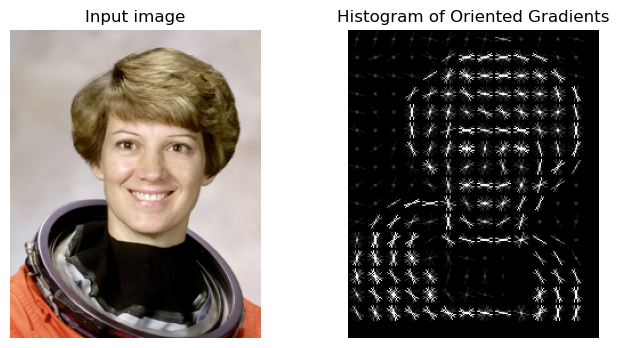

In [2]:
# load new image
image1 = data.astronaut()[:270,100:320]
print(image1.shape)

feature_vector=True,
bins = 8 
pixels_per_cell = 16
cells_per_block = 4 

# CREATE HOG FEATURES
(fd1, hog_feat1) = hog(
    image1,
    orientations=bins,
    pixels_per_cell=(pixels_per_cell, pixels_per_cell),
    cells_per_block=(cells_per_block, cells_per_block),
    block_norm="L2",
    visualize=True,
    feature_vector=True,
    channel_axis=-1
)
hog_feat1 = hog_feat1.astype("uint8")


# after implementation of the HoG function, run the following plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 4), sharex=True, sharey=True)

ax1.axis('off')
ax1.imshow(image1, cmap=plt.cm.gray)
ax1.set_title('Input image')

# Rescale histogram for better display
hog_image_rescaled = exposure.rescale_intensity(hog_feat1, in_range=(0, 10))

ax2.axis('off')
ax2.imshow(hog_image_rescaled, cmap=plt.cm.gray)
ax2.set_title('Histogram of Oriented Gradients')
plt.show()


---
**Task 2 (easy): Visualizing and understanding the HOG descriptor👩‍💻**
Change the parameters of the HOG descriptor and visualize how the feature descriptor changes.
1. Change the parameters for the HOG descriptor:

- the number of bins
- the number of pixels per cell
- the number of cells per block

and visually observe how the dimensionality and the features change.
2. The following cell loads an image of a cat. Use the HOG descriptor on this image.


---

(270, 220, 3)


Text(0.5, 1.0, 'Histogram of Oriented Gradients')

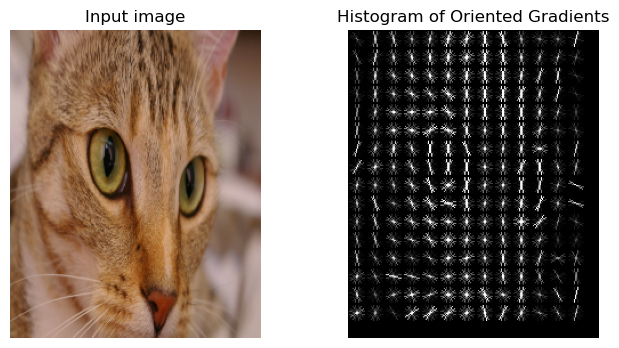

In [3]:
image2 = data.cat()[:270,:440:2]
print(image2.shape)


# Set HOG parameters
bins = 8                   # Number of bins for gradient directions
pixels_per_cell = (16, 16) # Number of pixels per cell
cells_per_block = (4, 4)   # Number of cells per block
# Number of Bins: This sets how many directions of edges (gradients) are captured. More bins mean more detail, as edges are broken down into finer angles, but it also makes the feature data bigger.
# Pixels per Cell: Cells are small patches of the image where edge directions are calculated. Bigger cells capture larger patterns, while smaller cells focus on fine details.
# Cells per Block: Blocks are groups of cells combined for smoothness. More cells in a block cover a larger area, making the features more consistent across different lighting or shadows.

# Compute HOG features and image
fd2, hog_image2 = hog(
    image2,
    orientations=bins,
    pixels_per_cell=pixels_per_cell,
    cells_per_block=cells_per_block,
    block_norm="L2",
    visualize=True,
    feature_vector=True,
    channel_axis=-1
)
# fd2 is the feature vector, hog_image contains the image

# after implementation of the HoG function, run the following plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 4), sharex=True, sharey=True)

ax1.axis('off')
ax1.imshow(image2, cmap=plt.cm.gray)
ax1.set_title('Input image')

# Rescale histogram for better display
hog_image_rescaled2 = exposure.rescale_intensity(hog_image2, in_range=(0, 10))

ax2.axis('off')
ax2.imshow(hog_image_rescaled2, cmap=plt.cm.gray)
ax2.set_title('Histogram of Oriented Gradients')


---
**Task 3 (easy): Comparing Hog Features👩‍💻**
This task will compare two HoG features of different images. 
1. For different settings visually compare the hog features
2. Calculate the normalized (use `np.linalg.norm`
 to normalize vectors) scalar product between the two feature vectors `fd1`
 and `fd2`
.     - What is the scalar product between two feature vectors? (compare it to the value of 1 )
    - Repeat the calculation for multiple HoG filter settings, notice a difference? 




**Hint**
Set `feature_vector`
=True in `hog`


3. Based on the cosine similarity (normalized inner product), explain how HoG features can be used to classify different images of cat/humans.


---

In [4]:
# Normalize the feature vectors
fd1_norm = fd1 / np.linalg.norm(fd1)
fd2_norm = fd2 / np.linalg.norm(fd2)

# Calculate the scalar product (cosine similarity)
cosine_similarity = np.dot(fd1_norm, fd2_norm)
print(f"Cosine Similarity between HOG features: {cosine_similarity:.3f}")


# A similarity of 1 means the vectors are identical in direction, 
# 0 means they are completely unrelated, 
# and -1 means they are opposite.
# Since HOG features represent edge and gradient patterns in an image, 
# a cosine similarity close to 1 indicates that the two images have very similar textures and shapes.

Cosine Similarity between HOG features: 0.430



---
**Task 4 (medium): Interpretation/ Understanding questions💡**
Select several images from the dataset (`peopleXY.jpg`
) and visually compare the HOG features of people and non-people images. 
1. How could HoG features be used to classify different objects in a larger image with multiple people? 

2. Explain how the HOG features use local information to create an understanding of the content of the full image? 


The code in the cell below visualizes the HoG features:

---

(800, 1200, 3)
 HoG feature vector shape: (47, 72, 4, 4, 8)
 HoG feature vector shape after vectorization: (433152,)


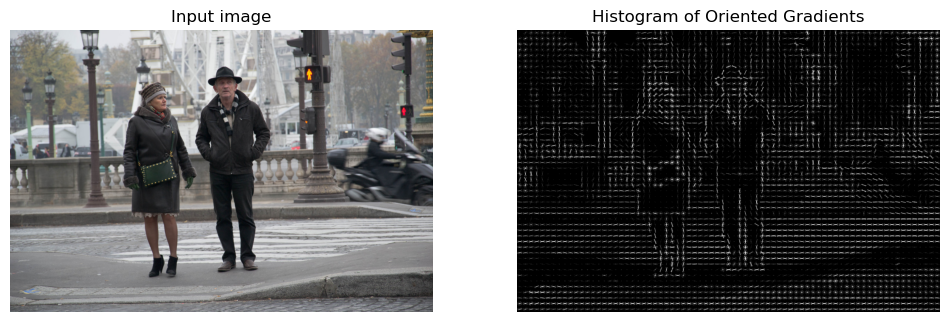

In [5]:
# load new image
fn =  "./data/people03.jpg"
image = plt.imread(fn)
print(image.shape)

feature_vector=True,
bins = 8 
pixels_per_cell = 16
cells_per_block = 4 

# Compute HOG.
(fd, hog_feat) = hog(
    image,
    orientations=bins,
    pixels_per_cell=(pixels_per_cell, pixels_per_cell),
    cells_per_block=(cells_per_block, cells_per_block),
    block_norm="L2",
    visualize=True,
    feature_vector=False,
    channel_axis=-1
)
hog_feat = hog_feat.astype("uint8")


print(f' HoG feature vector shape: {fd.shape}')
print(f' HoG feature vector shape after vectorization: {fd.reshape(-1).shape}')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), sharex=True, sharey=True)

ax1.axis('off')
ax1.imshow(image, cmap=plt.cm.gray)
ax1.set_title('Input image')

# Rescale histogram for better display
hog_image_rescaled = exposure.rescale_intensity(hog_feat, in_range=(0, 10))

ax2.axis('off')
ax2.imshow(hog_image_rescaled, cmap=plt.cm.gray)
ax2.set_title('Histogram of Oriented Gradients')

plt.show()

In [6]:
# 1
# HOG can be applied to smaller regions within a larger image. 
# By sliding a window across the image and extracting HOG features from each window, you can check each window for "people-like" patterns.

# 2
# Local Gradients: HOG calculates the gradients (changes in intensity) within each small cell. This provides details about the edges and textures in each part of the image.
# Building a Whole Picture: By combining these local gradient features from all cells, HOG creates a comprehensive description of the overall shape and structure in the image.
# Robust Representation: Because it focuses on small, local parts, HOG captures the essential shape and texture patterns without being affected much by lighting changes or noise across the image. This local information helps HOG "see" the object as a whole by piecing together the local patterns.